In [4]:
import torch

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())
import urllib.request

url = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"

with urllib.request.urlopen(url) as response:
    text = response.read().decode("utf-8")

print("Characters:", len(text))
print("First 500 characters:")
print(text[:500])

import re

tokens = re.findall(
    r"[a-z0-9]+(?:['’][a-z0-9]+)*|[.,!?;:]",
    text.lower()
)

print("Total tokens:", len(tokens))
print("Unique tokens:", len(set(tokens)))
print("First 40 tokens:", tokens[:40])

PyTorch version: 2.11.0+cpu
GPU available: False
Characters: 1115394
First 500 characters:
First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you know Caius Marcius is chief enemy to the people.

All:
We know't, we know't.

First Citizen:
Let us kill him, and we'll have corn at our own price.
Is't a verdict?

All:
No more talking on't; let it be done: away, away!

Second Citizen:
One word, good citizens.

First Citizen:
We are accounted poor
Total tokens: 250172
Unique tokens: 12380
First 40 tokens: ['first', 'citizen', ':', 'before', 'we', 'proceed', 'any', 'further', ',', 'hear', 'me', 'speak', '.', 'all', ':', 'speak', ',', 'speak', '.', 'first', 'citizen', ':', 'you', 'are', 'all', 'resolved', 'rather', 'to', 'die', 'than', 'to', 'famish', '?', 'all', ':', 'resolved', '.', 'resolved', '.', 'first']


In [7]:
from collections import Counter

split_index = int(len(tokens) * 0.9)
train_tokens = tokens[:split_index]
val_tokens = tokens[split_index:]

max_vocab = 8000
common_words = Counter(train_tokens).most_common(max_vocab - 1)

vocab = ["<unk>"] + [word for word, count in common_words]
stoi = {word: i for i, word in enumerate(vocab)}
itos = {i: word for word, i in stoi.items()}

train_ids = [stoi.get(word, 0) for word in train_tokens]
val_ids = [stoi.get(word, 0) for word in val_tokens]

train_unk = sum(word == "<unk>" for word in train_ids)
val_unk = sum(word == "<unk>" for word in val_ids)

print("Training tokens:", len(train_ids))
print("Validation tokens:", len(val_ids))
print("Vocabulary size:", len(vocab))
print("Training words mapped to <unk>:", train_unk)
print("Validation words mapped to <unk>:", val_unk)

train_unk = sum(token_id == 0 for token_id in train_ids)
val_unk = sum(token_id == 0 for token_id in val_ids)

print("Training words mapped to <unk>:", train_unk)
print("Validation words mapped to <unk>:", val_unk)
print("Validation <unk> percentage:", round(100 * val_unk / len(val_ids), 2), "%")

Training tokens: 225154
Validation tokens: 25018
Vocabulary size: 8000
Training words mapped to <unk>: 0
Validation words mapped to <unk>: 0
Training words mapped to <unk>: 3692
Validation words mapped to <unk>: 1499
Validation <unk> percentage: 5.99 %


In [8]:
import torch

sequence_length = 20
stride = 5

train_tensor = torch.tensor(train_ids, dtype=torch.long)
val_tensor = torch.tensor(val_ids, dtype=torch.long)

train_windows = train_tensor.unfold(0, sequence_length + 1, stride)
val_windows = val_tensor.unfold(0, sequence_length + 1, stride)

train_x = train_windows[:, :-1]
train_y = train_windows[:, -1]

val_x = val_windows[:, :-1]
val_y = val_windows[:, -1]

print("Training input shape:", train_x.shape)
print("Training target shape:", train_y.shape)
print("Validation input shape:", val_x.shape)
print("Validation target shape:", val_y.shape)
print("Example input:", " ".join(itos[int(i)] for i in train_x[0]))
print("Example target:", itos[int(train_y[0])])

Training input shape: torch.Size([45027, 20])
Training target shape: torch.Size([45027])
Validation input shape: torch.Size([5000, 20])
Validation target shape: torch.Size([5000])
Example input: first citizen : before we proceed any further , hear me speak . all : speak , speak . first
Example target: citizen


In [9]:
import torch.nn as nn

class NextWordRNN(nn.Module):
    def __init__(self, model_type, vocab_size, embedding_size=64, hidden_size=128):
        super().__init__()

        self.model_type = model_type
        self.embedding = nn.Embedding(vocab_size, embedding_size)

        rnn_classes = {
            "Simple RNN": nn.RNN,
            "Bidirectional RNN": nn.RNN,
            "LSTM": nn.LSTM,
            "GRU": nn.GRU,
        }

        self.bidirectional = model_type == "Bidirectional RNN"
        self.rnn = rnn_classes[model_type](
            input_size=embedding_size,
            hidden_size=hidden_size,
            batch_first=True,
            bidirectional=self.bidirectional
        )

        directions = 2 if self.bidirectional else 1
        self.output_layer = nn.Linear(hidden_size * directions, vocab_size)

    def forward(self, x):
        embedded = self.embedding(x)
        _, hidden = self.rnn(embedded)

        # LSTM returns (hidden state, cell state); we need the hidden state.
        if self.model_type == "LSTM":
            hidden = hidden[0]

        if self.bidirectional:
            # Join the final forward and backward hidden states.
            final_hidden = torch.cat((hidden[-2], hidden[-1]), dim=1)
        else:
            final_hidden = hidden[-1]

        return self.output_layer(final_hidden)


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model_names = ["Simple RNN", "Bidirectional RNN", "LSTM", "GRU"]

models = {
    name: NextWordRNN(name, vocab_size=len(vocab)).to(device)
    for name in model_names
}

test_input = train_x[:4].to(device)
test_output = models["Simple RNN"](test_input)

print("Device:", device)
print("Test output shape:", test_output.shape)
print("Expected shape:", (4, len(vocab)))

Device: cpu
Test output shape: torch.Size([4, 8000])
Expected shape: (4, 8000)


In [10]:
from torch.utils.data import TensorDataset, DataLoader

# Keep every fourth window to reduce CPU training time.
train_x_fit = train_x[::4].contiguous()
train_y_fit = train_y[::4].contiguous()

batch_size = 128

train_loader = DataLoader(
    TensorDataset(train_x_fit, train_y_fit),
    batch_size=batch_size,
    shuffle=True
)

val_loader = DataLoader(
    TensorDataset(val_x, val_y),
    batch_size=batch_size,
    shuffle=False
)

# Re-create the models with a fixed seed for reproducibility.
torch.manual_seed(42)
models = {
    name: NextWordRNN(name, vocab_size=len(vocab)).to(device)
    for name in model_names
}

print("Training examples:", len(train_x_fit))
print("Validation examples:", len(val_x))
print("Training batches per epoch:", len(train_loader))
print("Validation batches:", len(val_loader))

Training examples: 11257
Validation examples: 5000
Training batches per epoch: 88
Validation batches: 40


In [11]:
import time
import torch.nn as nn

num_epochs = 3
criterion = nn.CrossEntropyLoss()
history = {}

for name, model in models.items():
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    history[name] = []
    total_training_seconds = 0.0

    print(f"\nTraining {name}...")

    for epoch in range(1, num_epochs + 1):
        model.train()
        train_loss_sum = 0.0
        training_start = time.perf_counter()

        for x_batch, y_batch in train_loader:
            x_batch = x_batch.to(device)
            y_batch = y_batch.to(device)

            optimizer.zero_grad()
            logits = model(x_batch)
            loss = criterion(logits, y_batch)
            loss.backward()
            optimizer.step()

            train_loss_sum += loss.item() * len(x_batch)

        epoch_training_seconds = time.perf_counter() - training_start
        total_training_seconds += epoch_training_seconds
        train_loss = train_loss_sum / len(train_loader.dataset)

        model.eval()
        val_loss_sum = 0.0
        correct = 0

        with torch.no_grad():
            for x_batch, y_batch in val_loader:
                x_batch = x_batch.to(device)
                y_batch = y_batch.to(device)

                logits = model(x_batch)
                loss = criterion(logits, y_batch)

                val_loss_sum += loss.item() * len(x_batch)
                correct += (logits.argmax(dim=1) == y_batch).sum().item()

        val_loss = val_loss_sum / len(val_loader.dataset)
        val_accuracy = correct / len(val_loader.dataset)

        history[name].append({
            "epoch": epoch,
            "train_loss": train_loss,
            "val_loss": val_loss,
            "val_accuracy": val_accuracy
        })

        print(
            f"Epoch {epoch}/{num_epochs} | "
            f"train loss: {train_loss:.4f} | "
            f"val loss: {val_loss:.4f} | "
            f"val accuracy: {val_accuracy:.4f} | "
            f"training time: {epoch_training_seconds:.1f}s"
        )

    history[name + "_training_seconds"] = total_training_seconds
    print(f"{name} total training time: {total_training_seconds:.1f}s")


Training Simple RNN...
Epoch 1/3 | train loss: 7.1091 | val loss: 6.1497 | val accuracy: 0.0814 | training time: 4.6s
Epoch 2/3 | train loss: 5.9994 | val loss: 6.0309 | val accuracy: 0.1050 | training time: 4.4s
Epoch 3/3 | train loss: 5.8060 | val loss: 5.9530 | val accuracy: 0.1342 | training time: 4.1s
Simple RNN total training time: 13.0s

Training Bidirectional RNN...
Epoch 1/3 | train loss: 6.9707 | val loss: 6.0634 | val accuracy: 0.0880 | training time: 9.0s
Epoch 2/3 | train loss: 5.8248 | val loss: 5.9674 | val accuracy: 0.1260 | training time: 8.6s
Epoch 3/3 | train loss: 5.4317 | val loss: 5.9238 | val accuracy: 0.1312 | training time: 8.0s
Bidirectional RNN total training time: 25.5s

Training LSTM...
Epoch 1/3 | train loss: 7.1442 | val loss: 6.0787 | val accuracy: 0.0816 | training time: 8.5s
Epoch 2/3 | train loss: 5.9909 | val loss: 6.0510 | val accuracy: 0.0818 | training time: 7.9s
Epoch 3/3 | train loss: 5.8597 | val loss: 6.0310 | val accuracy: 0.0980 | training 

In [12]:
import math
import pandas as pd

rows = []

for name in model_names:
    final = history[name][-1]

    rows.append({
        "Model": name,
        "Validation Loss": final["val_loss"],
        "Perplexity": math.exp(final["val_loss"]),
        "Validation Accuracy": final["val_accuracy"],
        "Training Time (seconds)": history[name + "_training_seconds"]
    })

metrics_df = pd.DataFrame(rows).sort_values("Validation Loss")
display(metrics_df.round(4))

metrics_df.to_csv("metrics.csv", index=False)
print("Saved metrics.csv")


,Model,Validation Loss,Perplexity,Validation Accuracy,Training Time (seconds)
1,Bidirectional RNN,5.9238,373.8258,0.1312,25.5480
0,Simple RNN,5.9530,384.8908,0.1342,13.0462
3,GRU,6.0123,408.4172,0.1300,19.7659
2,LSTM,6.0310,416.1339,0.0980,24.1258


Saved metrics.csv


In [15]:
def generate_text(model, seed_ids, temperature, new_tokens=30):
    model.eval()
    generated = list(seed_ids)

    with torch.no_grad():
        for _ in range(new_tokens):
            context = generated[-sequence_length:]
            x = torch.tensor([context], dtype=torch.long, device=device)

            logits = model(x)[0] / temperature
            probabilities = torch.softmax(logits, dim=0)
            next_id = torch.multinomial(probabilities, num_samples=1).item()

            generated.append(next_id)

    return " ".join(itos[token_id] for token_id in generated)


# Use the same seed for every model and temperature.
seed_ids = [int(token_id) for token_id in train_x[0]]
print("Seed:", " ".join(itos[token_id] for token_id in seed_ids))

temperatures = [0.5, 1.0, 1.5]
torch.manual_seed(123)

for name, model in models.items():
    print(f"\n===== {name} =====")
    for temperature in temperatures:
        sample = generate_text(model, seed_ids, temperature)
        print(f"\nTemperature {temperature}:")
        print(sample)

Seed: first citizen : before we proceed any further , hear me speak . all : speak , speak . first

===== Simple RNN =====

Temperature 0.5:
first citizen : before we proceed any further , hear me speak . all : speak , speak . first , <unk> , to , to my , my , my the the <unk> . the thou <unk> the no of the purpose , so , and you , and

Temperature 1.0:
first citizen : before we proceed any further , hear me speak . all : speak , speak . first nothing well colour daughter fickle . do is : good ! you that people is of her tribunes all what one borne , by who arm'd , so the wing

Temperature 1.5:
first citizen : before we proceed any further , hear me speak . all : speak , speak . first twas angelo after counsel steeds margaret measure it ourselves in souls edward whose the safer sacrifice , more purpose those began are bona cry a we where therefore ? fever

===== Bidirectional RNN =====

Temperature 0.5:
first citizen : before we proceed any further , hear me speak . all : speak , speak 

In [16]:
import time
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

# Keep every fourth training window to make CPU training manageable.
train_x_fit = train_x[::4].contiguous()
train_y_fit = train_y[::4].contiguous()

train_loader = DataLoader(
    TensorDataset(train_x_fit, train_y_fit),
    batch_size=128,
    shuffle=True
)

val_loader = DataLoader(
    TensorDataset(val_x, val_y),
    batch_size=128,
    shuffle=False
)

# Reset all models so each one starts fresh, with reproducible initialization.
torch.manual_seed(42)
models = {
    name: NextWordRNN(name, vocab_size=len(vocab)).to(device)
    for name in model_names
}

num_epochs = 10
criterion = nn.CrossEntropyLoss()
history = {}

for name, model in models.items():
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    history[name] = []
    total_training_seconds = 0.0

    print(f"\nTraining {name}...")

    for epoch in range(1, num_epochs + 1):
        model.train()
        train_loss_sum = 0.0
        training_start = time.perf_counter()

        for x_batch, y_batch in train_loader:
            x_batch = x_batch.to(device)
            y_batch = y_batch.to(device)

            optimizer.zero_grad()
            logits = model(x_batch)
            loss = criterion(logits, y_batch)
            loss.backward()
            optimizer.step()

            train_loss_sum += loss.item() * len(x_batch)

        epoch_training_seconds = time.perf_counter() - training_start
        total_training_seconds += epoch_training_seconds
        train_loss = train_loss_sum / len(train_loader.dataset)

        model.eval()
        val_loss_sum = 0.0
        correct = 0

        with torch.no_grad():
            for x_batch, y_batch in val_loader:
                x_batch = x_batch.to(device)
                y_batch = y_batch.to(device)

                logits = model(x_batch)
                loss = criterion(logits, y_batch)

                val_loss_sum += loss.item() * len(x_batch)
                correct += (logits.argmax(dim=1) == y_batch).sum().item()

        val_loss = val_loss_sum / len(val_loader.dataset)
        val_accuracy = correct / len(val_loader.dataset)

        history[name].append({
            "epoch": epoch,
            "train_loss": train_loss,
            "val_loss": val_loss,
            "val_accuracy": val_accuracy
        })

        print(
            f"Epoch {epoch}/{num_epochs} | "
            f"train loss: {train_loss:.4f} | "
            f"val loss: {val_loss:.4f} | "
            f"val accuracy: {val_accuracy:.4f} | "
            f"training time: {epoch_training_seconds:.1f}s"
        )

    history[name + "_training_seconds"] = total_training_seconds
    print(f"{name} total training time: {total_training_seconds:.1f}s")


Training Simple RNN...
Epoch 1/10 | train loss: 7.1091 | val loss: 6.1497 | val accuracy: 0.0814 | training time: 3.9s
Epoch 2/10 | train loss: 5.9994 | val loss: 6.0309 | val accuracy: 0.1050 | training time: 4.8s
Epoch 3/10 | train loss: 5.8060 | val loss: 5.9530 | val accuracy: 0.1342 | training time: 3.8s
Epoch 4/10 | train loss: 5.5510 | val loss: 5.9111 | val accuracy: 0.1406 | training time: 3.9s
Epoch 5/10 | train loss: 5.3438 | val loss: 5.8707 | val accuracy: 0.1414 | training time: 4.5s
Epoch 6/10 | train loss: 5.1412 | val loss: 5.8675 | val accuracy: 0.1368 | training time: 4.0s
Epoch 7/10 | train loss: 4.9466 | val loss: 5.8524 | val accuracy: 0.1358 | training time: 3.8s
Epoch 8/10 | train loss: 4.7541 | val loss: 5.8585 | val accuracy: 0.1404 | training time: 4.3s
Epoch 9/10 | train loss: 4.5645 | val loss: 5.8720 | val accuracy: 0.1392 | training time: 3.7s
Epoch 10/10 | train loss: 4.3755 | val loss: 5.9176 | val accuracy: 0.1362 | training time: 4.1s
Simple RNN tota

In [17]:
import math
import pandas as pd

rows = []

for name in model_names:
    final = history[name][-1]

    rows.append({
        "Model": name,
        "Validation Loss": final["val_loss"],
        "Perplexity": math.exp(final["val_loss"]),
        "Validation Accuracy": final["val_accuracy"],
        "Training Time (seconds)": history[name + "_training_seconds"]
    })

metrics_df = pd.DataFrame(rows).sort_values("Validation Loss")
display(metrics_df.round(4))

metrics_df.to_csv("metrics.csv", index=False)
print("Saved metrics.csv")

,Model,Validation Loss,Perplexity,Validation Accuracy,Training Time (seconds)
2,LSTM,5.9124,369.6010,0.1404,82.3329
3,GRU,5.9142,370.2428,0.1402,63.6633
0,Simple RNN,5.9176,371.5118,0.1362,40.8635
1,Bidirectional RNN,6.2756,531.4409,0.1124,73.5767


Saved metrics.csv


In [18]:
import re

def detokenize(token_ids):
    words = [itos[int(token_id)] for token_id in token_ids]
    text = " ".join(words)
    text = re.sub(r"\s+([.,!?;:])", r"\1", text)
    return text

def generate_text(model, seed_ids, temperature, new_tokens=30):
    model.eval()
    generated = list(seed_ids)

    with torch.no_grad():
        for _ in range(new_tokens):
            context = generated[-sequence_length:]
            x = torch.tensor([context], dtype=torch.long, device=device)

            logits = model(x)[0] / temperature
            probabilities = torch.softmax(logits, dim=0)
            next_id = torch.multinomial(probabilities, num_samples=1).item()
            generated.append(next_id)

    return detokenize(generated)

seed_ids = [int(token_id) for token_id in train_x[0]]
temperatures = [0.5, 1.0, 1.5]
generated_samples = {}

torch.manual_seed(123)

with open("generated_samples.txt", "w", encoding="utf-8") as file:
    seed_text = detokenize(seed_ids)
    print("Seed:", seed_text)
    file.write(f"Seed: {seed_text}\n")

    for name, model in models.items():
        generated_samples[name] = {}
        print(f"\n===== {name} =====")
        file.write(f"\n===== {name} =====\n")

        for temperature in temperatures:
            sample = generate_text(model, seed_ids, temperature)
            generated_samples[name][temperature] = sample

            print(f"\nTemperature {temperature}:\n{sample}")
            file.write(f"\nTemperature {temperature}:\n{sample}\n")

print("\nSaved generated_samples.txt")


Seed: first citizen: before we proceed any further, hear me speak. all: speak, speak. first

===== Simple RNN =====

Temperature 0.5:
first citizen: before we proceed any further, hear me speak. all: speak, speak. first senator: then we, that his case, and <unk> the <unk> of the <unk>. coriolanus: no, ay, and so, and what, and

Temperature 1.0:
first citizen: before we proceed any further, hear me speak. all: speak, speak. first nothing well colour to be but, to bound the head company that ladies is of her tribunes all what one borne, by who arm'd pardon liberty, do

Temperature 1.5:
first citizen: before we proceed any further, hear me speak. all: speak, speak. first norfolk angelo after counsel, for murdering it ourselves in souls that lies the god sacrifice, seeking purpose, began me bona cry a we where therefore? some

===== Bidirectional RNN =====

Temperature 0.5:
first citizen: before we proceed any further, hear me speak. all: speak, speak. first citizen: i have thee to your, a

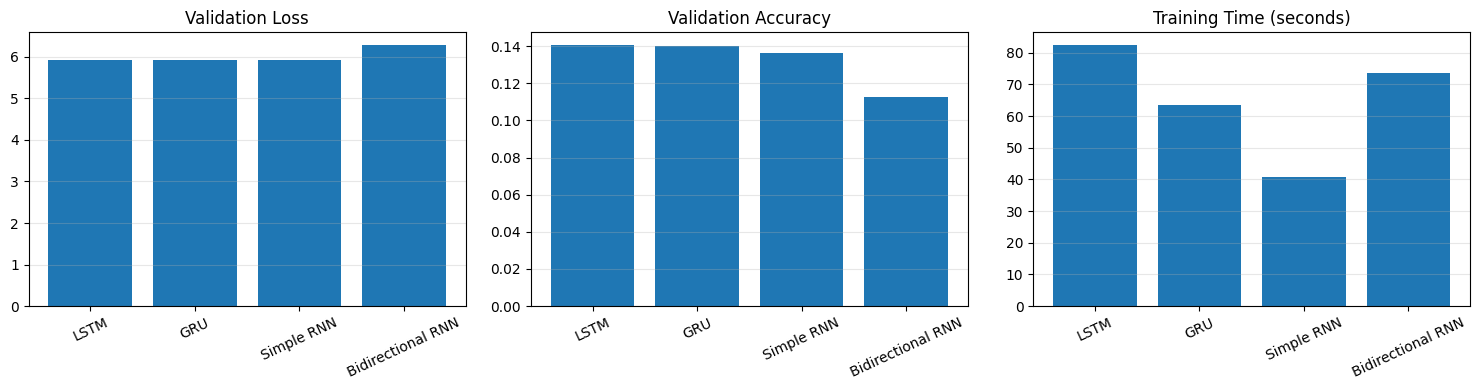

Saved model_comparison.png


In [19]:
import matplotlib.pyplot as plt

plot_df = metrics_df.copy()

columns = [
    ("Validation Loss", "Validation Loss"),
    ("Validation Accuracy", "Validation Accuracy"),
    ("Training Time (seconds)", "Training Time (seconds)")
]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (column, title) in zip(axes, columns):
    ax.bar(plot_df["Model"], plot_df[column])
    ax.set_title(title)
    ax.tick_params(axis="x", rotation=25)
    ax.grid(axis="y", alpha=0.3)

fig.tight_layout()
fig.savefig("model_comparison.png", dpi=200, bbox_inches="tight")
plt.show()

print("Saved model_comparison.png")